# M03 — Admisión magnética y retención espacial

**Pregunta:** ¿Cómo evita la partición espacial M03 la fuga entre líneas sin afirmar que hay una inversión?

**Nivel 2 · Prerrequisitos: notebook de fundamentos; lectura: 25 minutos.**


## Objetivos

Ejecute parser estricto y planificador geométrico sobre el fixture protocolario original versionado de 288 filas. No contiene respuesta magnética medida. Es ejemplo de partición/control de filtración, no de correcciones, gridding, continuación ni inversión.


## Preparación

Use el entorno pipeline Python 3.12 ya revisado. Este notebook no instala nada.
Importe el código del repositorio y confirme su archivo fuente.

In [1]:
import runpy, sys
from pathlib import Path

root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from magnetic_survey_json import parse_request
from magnetic_survey import plan_geometry

support = runpy.run_path(str(root / "tests/data/magnetic_survey_support.py"))
# Verifique la ubicación real del código fuente del planificador.
print(Path(__import__("magnetic_survey").__file__).name)


magnetic_survey.py


## Datos

Ejecute parser estricto y planificador geométrico sobre el fixture protocolario original versionado de 288 filas. No contiene respuesta magnética medida. Es ejemplo de partición/control de filtración, no de correcciones, gridding, continuación ni inversión.

**Archivos:** tests/data/magnetic_survey_support.py, tests/fixtures/magnetic_survey/generate.py, docs/methods/magnetic-survey/README.md

## Método

El contrato fija ENU en metros, grupos vuelo/fuente, bloques espaciales deterministas, holdout externo y pliegues con buffer. Filas del mismo grupo/bloque permanecen juntas; rango y cobertura se revisan antes de materializar verosimilitud. Controla filtración espacial, pero no corrige variación diurna, IGRF, altura ni grillas del proveedor.

El fixture entrega coordenadas este/norte/arriba en metros, IDs de grupo de vuelo, ancho de bloque espacial explícito y buffer de 200 m. El planificador une filas que comparten grupo de vuelo o bloque espacial; conexiones transitivas forman unidades indivisibles. Ordena unidades determinísticamente, retiene cerca de una quinta parte para evaluación externa y crea pliegues de desarrollo. En cada pliegue se eliminan filas de ajuste a distancia b o menor de validación o holdout: se conserva i solo si minⱼ∈H ‖xᵢ−xⱼ‖₂>b. Es una regla de control de filtración, no una corrección magnética. La partición espacial train/test de Verde es la referencia relacionada [API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html).

El planificador también comprueba rango geométrico: para coordenadas horizontales centradas X=[1,e−ē,n−n̄] se exige rango(X)=3, evitando particiones colapsadas a una línea. Verifica soporte de coordenadas, no identificabilidad de propiedades físicas. El fixture tiene doce líneas de vuelo y 288 posiciones, pero respuesta magnética cero. La figura muestra pertenencia exacta de filas al pliegue 1, incluidas exclusiones por buffer. La elegibilidad actual niega explícitamente aceptación online/completa: derechos, linaje, verosimilitud validada y enlace del optimizador siguen sin resolverse.

Ejecute el método del producto sobre el control declarado.

In [2]:
raw = support["encode"](support["request"]())
# Valide los bytes serializados exactos y calcule el sello geométrico determinista.
handle = parse_request(raw)
plan = plan_geometry(handle)
print(
    {
        "esquema": handle.metadata()["schema"],
        "hash_particion": plan["partition"]["sha256"],
        "filas_outer": len(plan["partition"]["outer_rows"]["data"]),
        "pliegues": len(plan["partition"]["folds"]),
        "inversion_ejecutada": False,
    }
)


{'esquema': 'magnetic-survey-inversion-1', 'hash_particion': '18c36c658217ee39da1c3cdda336389f4b0a0d8115c928b6707a114e1753e12e', 'filas_outer': 72, 'pliegues': 3, 'inversion_ejecutada': False}


La partición espacial bloqueada es preferible a dividir puntos al azar en líneas correlacionadas. Verde documenta partición espacial train/test ([referencia API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html)); el producto además sella grupos y aplica buffer a filas retenidas. Los módulos actuales ejecutan parser/geometría: no corrección magnética, núcleo ni optimizador.
Use directamente los índices de filas devueltos por el planificador. La figura cartografía el diseño de partición con ejes físicos en metros; sus categorías codifican la política de ajuste/holdout, nunca amplitud magnética.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Graficar índices exactos del planificador sobre geometría local creada; los colores solo codifican partición.
meta = handle.metadata()
xyz = np.asarray(meta["geometry"]["receivers_m"]["data"], dtype=float).reshape(-1, 3)
externo = np.asarray(plan["partition"]["outer_rows"]["data"], dtype=int)
f = plan["partition"]["folds"][0]
ajuste = np.asarray(f["fit_rows"]["data"], dtype=int)
validacion = np.asarray(f["validation_rows"]["data"], dtype=int)
buffer = np.asarray(f["buffered_rows"]["data"], dtype=int)
desarrollo = set(plan["partition"]["development_rows"]["data"])
assert not (set(externo) & desarrollo) and not (
    set(ajuste) & set(validacion) or set(ajuste) & set(buffer) or set(validacion) & set(buffer)
)


### Graficar índices de partición espacial

Los grupos de filas verificados se ubican en las posiciones reales de receptor; el mapa muestra dónde caen ajuste, validación, buffer y reserva exterior en el levantamiento.

{'externo': 72, 'ajuste': 144, 'validacion': 72, 'buffer': 0, 'método_completo_aceptado': False, 'fuente_de_campo_verificada': False, 'verdad_geológica_conocida': False, 'admitido_en_línea': False}


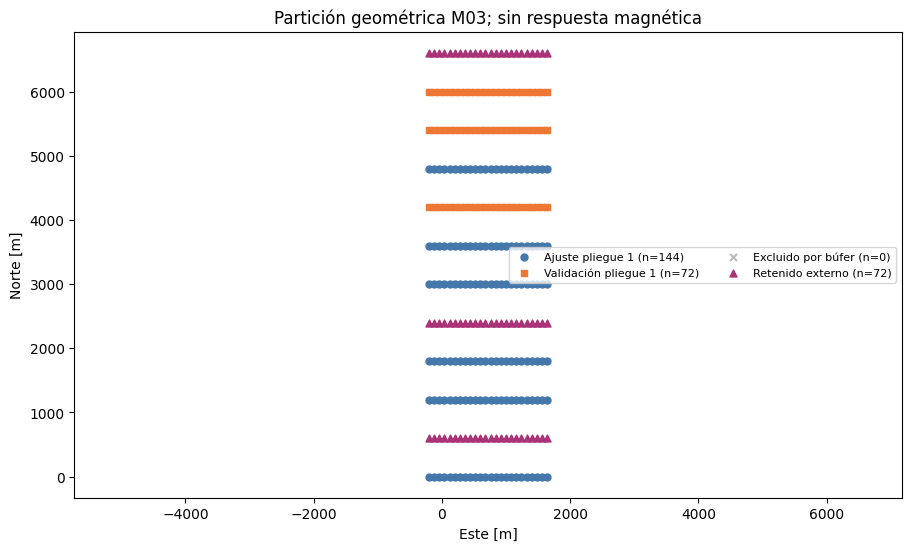

In [4]:
# Graficar índices de partición espacial.
fig, ax = plt.subplots(figsize=(9, 5.4), constrained_layout=True)
for ids, etiqueta, color, marcador in [
    (ajuste, "Ajuste pliegue 1", "#4477aa", "o"),
    (validacion, "Validación pliegue 1", "#ee7733", "s"),
    (buffer, "Excluido por búfer", "#bbbbbb", "x"),
    (externo, "Retenido externo", "#aa3377", "^"),
]:
    ax.scatter(xyz[ids, 0], xyz[ids, 1], label=f"{etiqueta} (n={len(ids)})", c=color, marker=marcador, s=25)
ax.set(xlabel="Este [m]", ylabel="Norte [m]", title="Partición geométrica M03; sin respuesta magnética")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(ncol=2, fontsize=8)
print(
    {
        "externo": len(externo),
        'ajuste': len(ajuste),
        "validacion": len(validacion),
        "buffer": len(buffer),
        "método_completo_aceptado": plan["claims"]["full_method_accepted"],
        "fuente_de_campo_verificada": plan["claims"]["field_source_verified"],
        "verdad_geológica_conocida": plan["claims"]["geology_truth_known"],
        "admitido_en_línea": plan["claims"]["online_admitted"],
    }
)
plt.show()


### Inspección visual de la geometría de receptores codificada

El mapa muestra coordenadas de receptores y grupos protocolarios antes de interpretar el planificador. Puede revelar un orden de coordenadas incorrecto o un bloque mal ubicado, pero todas las respuestas son cero por construcción. La figura solo comprueba geometría y serialización; no muestra anomalías magnéticas, calidad de cobertura ni separación predictiva.


In [5]:
# Vuelva a analizar los mismos bytes como paso independiente.
handle_repeat = parse_request(raw)
print(handle_repeat.metadata()["observations"]["values_sha256"])


71c642b31e5890a15ef92f3cbeba34edfb6e2e9f63079ecbda13a89d426f7d8b


Recalcule el plan geométrico sellado y compruebe determinismo.

In [6]:
# Recalcule el plan geométrico sellado y compruebe determinismo.
plan_repeat = plan_geometry(handle_repeat)
print(plan_repeat["partition"]["sha256"] == plan["partition"]["sha256"])


True


Calcule el hash canónico de identidad de partición devuelta por el pipeline.

In [7]:
# Calcule el hash canónico de identidad de partición devuelta por el pipeline.
from magnetic_survey_json import digest

print(digest(plan["partition"]))


e9393ca2a06106e09bc26583f7d26d23c784788df0beecf3da3e34da1b61883e


Una solicitud malformada es control negativo, no un sondeo alternativo reducido.

In [8]:
# Una solicitud malformada es control negativo, no un sondeo alternativo reducido.
from magnetic_survey_json import InputError

try:
    parse_request(raw + b"x")
except InputError as error:
    print("refused:", error.code)


refused: type


El primer mapa muestra las funciones asignadas por el planificador en sus coordenadas este/norte reales. Este gráfico complementario agrega los registros sellados de cada pliegue para mostrar cómo la reserva externa, la validación y las exclusiones por búfer reducen el conjunto de ajuste. Son conteos de geometría de partición; el fixture no contiene respuesta magnética y no informa desempeño predictivo ni cobertura de terreno.

Compare los conteos retenidos de ajuste, validación y búfer entre los pliegues planificados.

{'Pliegue 1': {'ajuste': 144, 'validación': 72, 'búfer': 0}, 'Pliegue 2': {'ajuste': 144, 'validación': 72, 'búfer': 0}, 'Pliegue 3': {'ajuste': 144, 'validación': 72, 'búfer': 0}}


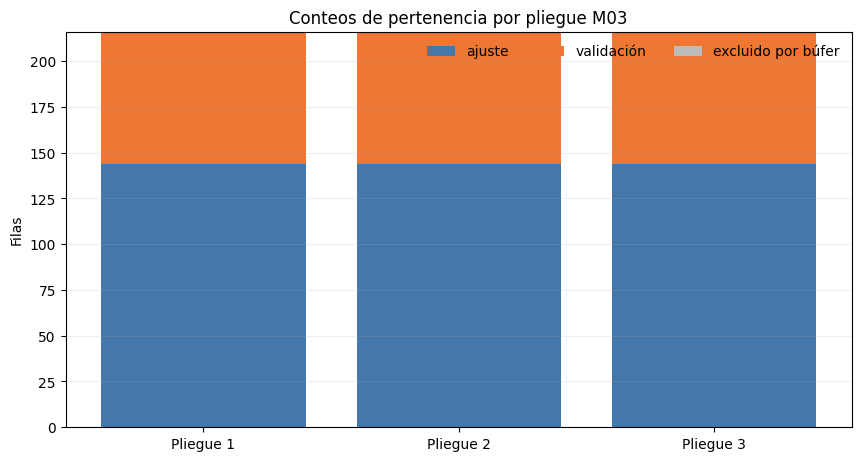

In [9]:
# Agregue los índices exactos del planificador para cada pliegue predefinido.
import numpy as np
import matplotlib.pyplot as plt

folds = plan["partition"]["folds"]
labels = [f"Pliegue {i + 1}" for i in range(len(folds))]
fit_n = [len(f["fit_rows"]["data"]) for f in folds]
validation_n = [len(f["validation_rows"]["data"]) for f in folds]
buffer_n = [len(f["buffered_rows"]["data"]) for f in folds]
x = np.arange(len(folds))
fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
ax.bar(x, fit_n, label="ajuste", color="#4477aa")
ax.bar(x, validation_n, bottom=fit_n, label="validación", color="#ee7733")
bottom = np.asarray(fit_n) + np.asarray(validation_n)
ax.bar(x, buffer_n, bottom=bottom, label="excluido por búfer", color="#bbbbbb")
ax.set(xticks=x, xticklabels=labels, ylabel="Filas", title="Conteos de pertenencia por pliegue M03")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", alpha=0.2)
print(
    {etiqueta: {"ajuste": a, "validación": b, "búfer": c} for etiqueta, a, b, c in zip(labels, fit_n, validation_n, buffer_n)}
)
plt.show()


Las barras son conteos directos de los índices serializados del planificador, no una segunda implementación de partición. Un búfer amplio puede reducir mucho las filas de ajuste, mientras los conteos de validación permanecen fijados por el pliegue sellado; el compromiso queda visible antes de considerar una respuesta o inversión. La reserva externa no aparece en estas categorías de desarrollo. El gráfico permite auditar el soporte geométrico disponible, pero no demuestra generalización de un estimador magnético futuro.

## Resultados

La ejecución confirma el esquema y la partición geométrica, no el procesamiento magnético M03 ni una predicción retenida. El plan recién calculado asigna 72 de 288 filas protocolarias a la reserva externa. Cada uno de los tres pliegues contiene 144 filas de ajuste y 72 de validación, sin filas en el búfer. No se ejecutó una inversión: la respuesta del fixture es nula y el planificador solo usa geometría y metadatos. No reduzca el búfer ni invente mediciones si falla la admisión.

## Resumen

La agrupación espacial y la reserva externa de 72 filas se calculan correctamente, pero el protocolo no contiene respuesta magnética medida. El planificador demuestra control de filtración únicamente; correcciones M03, nivelación de líneas, gridding y predicción retenida no se probaron.





## Referencias

- https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html